# Leyenda: Deliverable 2, image denoising with a convolutional auto-encoder

## 1. Context

TouNum digitises paper archives. Scans have variable quality (noise, blur), which hurts the next steps of the workflow, in particular captioning. This notebook builds a model that removes noise from photographs.

### What this notebook contains

1. The file loading code.
2. The denoising code (two convolutional auto-encoders), with explanations.
3. A case study.

### Our interpretation of the "case study" (not stated in the subject)

We show what denoising gains **and what it costs** (loss of fine detail), with numbers: PSNR and SSIM against a classical filter and against the noisy input.

### Assumptions to keep in mind

- The dataset has **no noisy images**. We generate the noise ourselves from clean photos (Gaussian noise). Real scan noise is different: this is a simplifying assumption.
- Images are resized to 128x128 RGB. Non-square images are squashed, not cropped: assumed choice.
- Only photographs are used (the denoiser sits after the photo / not photo classifier of Deliverable 1).

*Sections: 2 loading, 3 models, 4 training, 5 results, 6 case study, 7 analysis, limits and improvements, 8 the recommendation put into practice.*

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

from src.config import BATCH_SIZE, IMG_SIZE, NOISE_RANGE, NOISE_STD, SEED
from src.data import make_dataset, photo_splits

keras.utils.set_random_seed(SEED)
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    # Memory growth: TensorFlow takes the GPU memory it needs, not everything at once (2 GB cards).
    tf.config.experimental.set_memory_growth(gpus[0], True)
print("GPU:", [g.name for g in gpus] or "none (the training would be slow on CPU)")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)
print(f"IMG_SIZE={IMG_SIZE} | BATCH_SIZE={BATCH_SIZE} | NOISE_STD={NOISE_STD} | SEED={SEED}")

I0000 00:00:1792185281.502085  887635 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792185282.688951  887635 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: ['/physical_device:GPU:0']
TensorFlow 2.21.0 | Keras 3.15.1 | numpy 2.5.4 | matplotlib 3.11.2
IMG_SIZE=128 | BATCH_SIZE=16 | NOISE_STD=0.1 | SEED=42


## 2. Loading the files

### Split first, noise after

We split the **list of file paths** before any noise exists. The split is the one made for Deliverable 1 (stored in `protocol/manifest.csv`, 70 / 15 / 15, checked: no duplicate image in two sets). So an image never trains one model and tests another. Only photographs are kept.

### Reading without filling the memory

`make_dataset` (in `src/data.py`) builds a `tf.data` pipeline: it reads, resizes to 128x128 and adds the noise **batch by batch**. The dataset is never loaded whole in memory (images are `uint8` in the buffers, `float32` in [0, 1] only for the current batch). It returns pairs `(noisy image, clean image)`: the noisy one is the input of the model, the clean one is the target.

### Noise: random in training, fixed in validation and test

- **Training:** new noise at every epoch. The model never sees the same noisy image twice (free data augmentation).
- **Validation / test:** noise generated from a fixed seed, so two models are compared on **exactly the same** noisy images. This holds as long as the batch size is the same for all the models.

In [2]:
train_paths, val_paths, test_paths = photo_splits()
print(f"photos: train {len(train_paths)} | val {len(val_paths)} | test {len(test_paths)}")
assert not (set(train_paths) & set(val_paths) | set(train_paths) & set(test_paths) | set(val_paths) & set(test_paths))

train_ds = make_dataset(train_paths, training=True)
val_ds = make_dataset(val_paths, training=False)
test_ds = make_dataset(test_paths, training=False)

noisy, clean = next(iter(val_ds))
print("one batch: noisy", noisy.shape, noisy.dtype, "| clean", clean.shape, clean.dtype)
print(f"values in [{float(noisy.numpy().min()):.2f}, {float(noisy.numpy().max()):.2f}] (noisy) | "
      f"[{float(clean.numpy().min()):.2f}, {float(clean.numpy().max()):.2f}] (clean)")

# The validation noise is really fixed: a second pass gives the same pixels.
noisy_again, _ = next(iter(val_ds))
print("same validation noise on a second pass:", bool(np.array_equal(noisy.numpy(), noisy_again.numpy())))

photos: train 6995 | val 1499 | test 1499
one batch: noisy (16, 128, 128, 3) <dtype: 'float32'> | clean (16, 128, 128, 3) <dtype: 'float32'>
values in [0.00, 1.00] (noisy) | [0.00, 1.00] (clean)
same validation noise on a second pass: True


### What the model receives

Top row: the noisy input. Bottom row: the clean target. The model has to learn the way from top to bottom.

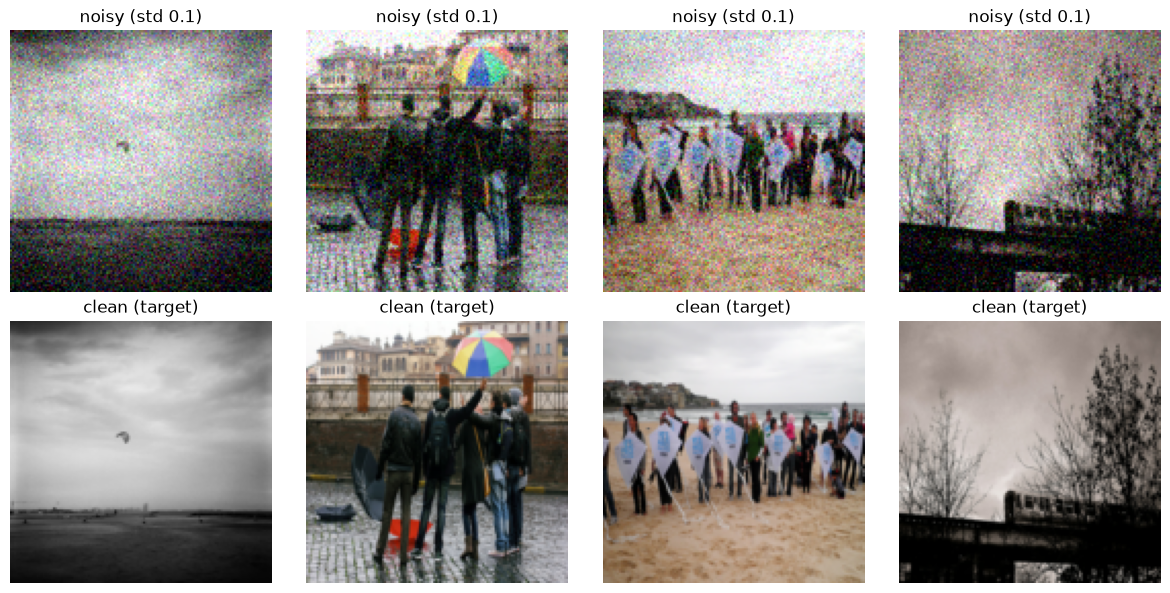

In [3]:
n_show = 4
fig, axes = plt.subplots(2, n_show, figsize=(3 * n_show, 6))
for i in range(n_show):
    axes[0, i].imshow(noisy[i]); axes[0, i].set_title(f"noisy (std {NOISE_STD})")
    axes[1, i].imshow(clean[i]); axes[1, i].set_title("clean (target)")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. The models

Both models take the noisy image (128x128x3, in [0, 1]) and output an image of the same shape. The last layer is a sigmoid so that the output stays in [0, 1], like the clean target. Loss: **MSE** (mean of the squared pixel differences between the output and the clean image). Optimizer: **Adam**, learning rate 1e-3.

### 3.1 Baseline: convolutional auto-encoder

- **Encoder:** 3 x (Conv 3x3 + ReLU + MaxPool 2) with 32, 64, 128 filters. The image goes from 128x128 to a 16x16x128 *bottleneck*. The convolutions detect patterns, the pooling halves the size and forces the network to keep only what is useful.
- **Decoder:** 3 x (Conv 3x3 + ReLU + UpSampling 2) with 128, 64, 32 filters (mirror of the encoder). `UpSampling2D` repeats pixels and has no weight: the convolution before it learns the content.
- **Output:** Conv with 3 filters (R, G, B) and a sigmoid.

The bottleneck holds 16x16x128 = 32,768 values for 128x128x3 = 49,152 in the input. The pooling also loses the exact position of the details: the output risks being a bit blurry.

In [4]:
def build_autoencoder():
    """Baseline convolutional auto-encoder: noisy image in, clean image out.

    Encoder: 3 x (Conv 3x3 + ReLU + MaxPool 2) with 32-64-128 filters, which
    compresses 128x128x3 into a 16x16x128 "bottleneck".
    Decoder: 3 x (Conv 3x3 + ReLU + UpSampling 2), then a Conv with 3 filters and a
    sigmoid to get back an RGB image in [0, 1].
    """
    # Same seed as the rest of the project: same initial weights at every run.
    keras.utils.set_random_seed(SEED)

    model = keras.Sequential([
        # No Rescaling layer: make_dataset already gives float32 in [0, 1].
        keras.Input((IMG_SIZE, IMG_SIZE, 3)),

        # Encoder. padding="same" keeps the size, only the pooling halves it.
        keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),    # 128 -> 64
        keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),    # 64 -> 32
        keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
        keras.layers.MaxPooling2D(2),    # 32 -> 16 (bottleneck)

        # Decoder, mirror of the encoder (128-64-32 filters).
        # UpSampling2D repeats pixels (no weights), the Conv before it learns the content.
        keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
        keras.layers.UpSampling2D(2),    # 16 -> 32
        keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
        keras.layers.UpSampling2D(2),    # 32 -> 64
        keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        keras.layers.UpSampling2D(2),    # 64 -> 128

        # Sigmoid: the output stays in [0, 1], like the clean target image.
        keras.layers.Conv2D(3, 3, padding="same", activation="sigmoid"),
    ], name="autoencoder")

    # MSE: pixel-by-pixel difference between the output and the clean image.
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return model

In [5]:
autoencoder = build_autoencoder()
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 333,955 (1.27 MB)

 Trainable params: 333,955 (1.27 MB)

 Non-trainable params: 0 (0.00 B)

### 3.2 Improved model: U-Net (skip connections)

Same network, plus **skip connections**: the output of each encoder block (before its pooling) is concatenated with the decoder features of the **same resolution**. The decoder then has two sources: the deep but coarse content coming from the bottleneck, and the precise details of the encoder. The shortcut also helps the gradient to flow during training.

`Concatenate` stacks the channels side by side, and the next convolution learns what to keep from each source. (A ResNet adds the two sources instead; it needs the same shape and is mostly used to train very deep networks.)

**Risk:** the full-resolution skip also carries the noisy pixels. The network may learn to copy the noise. We do not assume the U-Net is better: it is measured in the comparison.

In [6]:
def build_unet():
    """Same network as build_autoencoder, plus U-Net skip connections.

    Each decoder level receives, next to the up-sampled features, the encoder
    features of the SAME resolution (Concatenate). The decoder can then reuse
    the fine details that the 16x16 bottleneck loses. Risk: the skip at full
    resolution carries the noisy pixels too, so the network may copy the noise:
    this is measured in the comparison, not assumed.
    """
    keras.utils.set_random_seed(SEED)

    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))

    # Encoder. c1, c2, c3 are kept (before the pooling) for the skip connections.
    c1 = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)    # 128x128
    x = keras.layers.MaxPooling2D(2)(c1)                                          # 64
    c2 = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)         # 64x64
    x = keras.layers.MaxPooling2D(2)(c2)                                          # 32
    c3 = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)        # 32x32
    x = keras.layers.MaxPooling2D(2)(c3)                                          # 16 (bottleneck)

    # Decoder. After each UpSampling the resolution matches the encoder level c3, c2, c1.
    x = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)                                           # 32
    x = keras.layers.Concatenate()([x, c3])                                       # 128 + 128 channels
    x = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)                                           # 64
    x = keras.layers.Concatenate()([x, c2])                                       # 64 + 64 channels
    x = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)                                           # 128
    x = keras.layers.Concatenate()([x, c1])                                       # 32 + 32 channels

    outputs = keras.layers.Conv2D(3, 3, padding="same", activation="sigmoid")(x)

    model = keras.Model(inputs, outputs, name="unet")
    # Same loss and optimizer as the baseline: only the skip connections differ.
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return model

In [7]:
unet = build_unet()
unet.summary()
print(f"parameters: baseline {autoencoder.count_params():,} | U-Net {unet.count_params():,}")

Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 128, 128,  │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 64, 64,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 32, 32,    │          0 │ conv2d_8[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_4[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 16, 16,    │          0 │ conv2d_9[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 16, 16,    │    147,584 │ max_pooling2d_5[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_3     │ (None, 32, 32,    │          0 │ conv2d_10[0][0]   │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ up_sampling2d_3[… │
│ (Concatenate)       │ 256)              │            │ conv2d_9[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 32, 32,    │    147,520 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_4     │ (None, 64, 64,    │          0 │ conv2d_11[0][0]   │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 64, 64,    │          0 │ up_sampling2d_4[… │
│ (Concatenate)       │ 128)              │            │ conv2d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 64, 64,    │     36,896 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_5     │ (None, 128, 128,  │          0 │ conv2d_12[0][0]   │
│ (UpSampling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 128, 128,  │          0 │ up_sampling2d_5[… │
│ (Concatenate)       │ 64)               │            │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 128, 128,  │      1,731 │ concatenate_2[0]

 Total params: 426,979 (1.63 MB)

 Trainable params: 426,979 (1.63 MB)

 Non-trainable params: 0 (0.00 B)

parameters: baseline 333,955 | U-Net 426,979


## 4. Training

### What "doing nothing" scores

Before training anything, we measure the error of the **noisy input itself** against the clean image. This is the reference: a model that does not get below it is worse than doing nothing, so it is useless. We use the validation set (never the test set) for every decision.

The PSNR (peak signal-to-noise ratio, in dB, higher is better) is computed from the MSE: `PSNR = 10 * log10(1 / MSE)` for images in [0, 1].

In [8]:
# Sum of the squared pixel differences over the whole validation set, then the mean.
sq_err, n_values = 0.0, 0
for noisy_batch, clean_batch in val_ds:
    sq_err += float(tf.reduce_sum(tf.square(noisy_batch - clean_batch)))
    n_values += int(tf.size(clean_batch))
MSE_NOISY = sq_err / n_values
print(f"Validation, noisy input vs clean: MSE {MSE_NOISY:.5f} | PSNR {10 * np.log10(1 / MSE_NOISY):.2f} dB")

Validation, noisy input vs clean: MSE 0.00905 | PSNR 20.43 dB


### Training settings

- **Input / target:** the noisy image is the input, the clean image is the target.
- **Loss:** MSE, **optimizer:** Adam (learning rate 1e-3), **batch size:** 16 (`BATCH_SIZE`, same for every model because the validation noise depends on it).
- **Epoch, batch, iteration:** one epoch is one pass over the 6,995 training photos; with batches of 16 that is 438 iterations (weight updates) per epoch. The noise is redrawn at each epoch.
- **Early stopping:** we stop when the validation loss has not improved for `PATIENCE` epochs and go back to the best weights. It limits overfitting without choosing the number of epochs by hand (`MAX_EPOCHS` is only an upper bound).
- **Saved files:** the best weights are written to `models/` with a timestamp in the name (never overwritten), next to the loss history. `train_or_load` reloads the latest weights of a model instead of training again, so the notebook can be re-run quickly. Set `RETRAIN = True` to train again.

In [9]:
import json
import time
from datetime import datetime
from pathlib import Path

MODELS = Path("models")
MODELS.mkdir(exist_ok=True)
# 30 epochs were not enough for the baseline (the loss was still decreasing): 60 max, stop after 5 epochs without improvement.
MAX_EPOCHS, PATIENCE = 60, 5
RETRAIN = False   # True: ignore the saved weights and train again


def train_or_load(name, model, train_data=None, val_data=None):
    """Train `model` (or reload its latest saved weights) and return its loss history."""
    # The timestamp format sorts alphabetically, so the last file is the most recent.
    # [0-9]*: the name must be followed by a date, so that "unet" does not also match "unet_multi".
    saved = sorted(MODELS.glob(f"d2_{name}_[0-9]*.weights.h5"))
    if saved and not RETRAIN:
        weights = saved[-1]
        model.load_weights(weights)
        history = json.loads(weights.with_name(weights.name.replace(".weights.h5", "_history.json")).read_text())
        print(f"Reloaded {weights.name} ({len(history['loss'])} epochs), no training.")
        return history

    # By default the training and validation sets of the notebook (noise level 0.1).
    train_data = train_ds if train_data is None else train_data
    val_data = val_ds if val_data is None else val_data
    # New file name at every training: an old result is never overwritten.
    weights = MODELS / f"d2_{name}_{datetime.now():%Y%m%d_%H%M%S}.weights.h5"
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        # Writes the best weights as soon as they are found: nothing is lost if the run is interrupted.
        keras.callbacks.ModelCheckpoint(weights, monitor="val_loss", save_best_only=True, save_weights_only=True),
    ]
    t0 = time.time()
    fit = model.fit(train_data, validation_data=val_data, epochs=MAX_EPOCHS, callbacks=callbacks, verbose=2,
                    shuffle=False)   # the dataset is already shuffled by tf.data; avoids a Keras warning
    history = {k: [float(v) for v in vals] for k, vals in fit.history.items()}
    weights.with_name(weights.name.replace(".weights.h5", "_history.json")).write_text(json.dumps(history))
    print(f"Trained {len(history['loss'])} epochs in {time.time() - t0:.0f} s, best weights in {weights.name}")
    return history


def plot_loss(history, title, reference=None):
    """Train and validation loss per epoch, with the error of the noisy input as a reference."""
    reference = MSE_NOISY if reference is None else reference   # error of the noisy input on the validation set used
    epochs = np.arange(1, len(history["loss"]) + 1)
    best = int(np.argmin(history["val_loss"]))
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, history["loss"], marker="o", label="train")
    plt.plot(epochs, history["val_loss"], marker="o", label="validation")
    plt.axhline(reference, color="gray", linestyle="--", label="noisy input (doing nothing)")
    plt.axvline(best + 1, color="green", alpha=0.4, label=f"best epoch ({best + 1})")
    plt.yscale("log")   # the loss spans a large range at the beginning
    plt.xlabel("epoch"); plt.ylabel("MSE (log scale)"); plt.title(title)
    plt.grid(alpha=0.3); plt.legend()
    plt.show()

### 4.1 Baseline auto-encoder

Reloaded d2_autoencoder_20261013_214818.weights.h5 (50 epochs), no training.


/home/asmax/ds-cesi/leyenda/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(store)


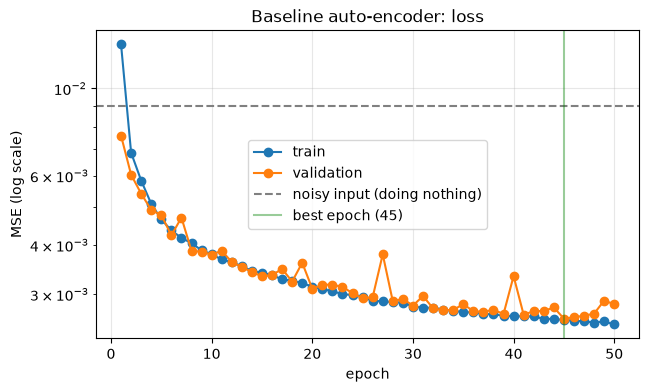

In [10]:
history_ae = train_or_load("autoencoder", autoencoder)
plot_loss(history_ae, "Baseline auto-encoder: loss")

### 4.2 U-Net

Same settings as the baseline (loss, optimizer, batch size, `MAX_EPOCHS`, `PATIENCE`): the only difference between the two runs is the skip connections.

Reloaded d2_unet_20261013_215357.weights.h5 (60 epochs), no training.


/home/asmax/ds-cesi/leyenda/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 2 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(store)


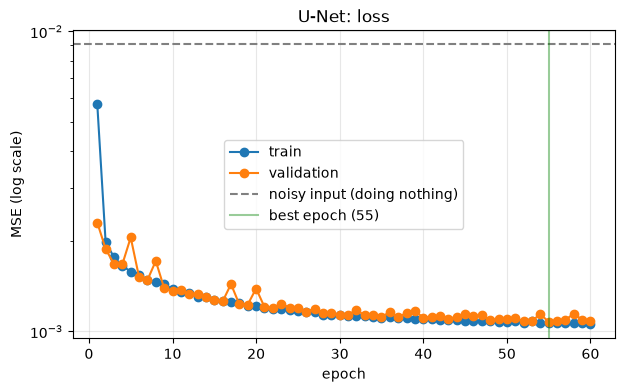

In [11]:
history_unet = train_or_load("unet", unet)
plot_loss(history_unet, "U-Net: loss")

## 5. Results

### 5.1 Metrics and the classical reference

Two metrics, both computed per image against the clean image, then averaged (images in [0, 1], `max_val=1`):

- **PSNR** (peak signal-to-noise ratio, in dB, higher is better): it is the MSE on a logarithmic scale, `10 * log10(1 / MSE)`. +3 dB means the error is halved. It measures pixel errors, not how the image looks.
- **SSIM** (structural similarity, 1 = identical, higher is better): it compares local brightness, contrast and structure in small windows. It is closer to what the eye sees and it drops when edges and textures are blurred, which is what we want to check here.

We compare four things on the **test set**: the noisy input (doing nothing), a **classical filter** (Gaussian or median, the usual first answer to noise), the baseline auto-encoder and the U-Net. If a deep model does not beat a simple filter, it is not worth its cost.

The filter strength is chosen on the **validation** set (never on the test set): a Gaussian filter smooths with a kernel of width `sigma`, a median filter replaces each pixel by the median of its `k x k` neighbours. A stronger filter removes more noise but also more detail.

In [12]:
from scipy import ndimage
import pandas as pd


def score(ds, denoise):
    """Per-image PSNR and SSIM of `denoise(noisy batch)` against the clean images of `ds`."""
    psnr, ssim = [], []
    for noisy_batch, clean_batch in ds:
        out = denoise(noisy_batch.numpy())
        psnr.append(tf.image.psnr(clean_batch, out, max_val=1.0).numpy())
        ssim.append(tf.image.ssim(clean_batch, out, max_val=1.0).numpy())
    return np.concatenate(psnr), np.concatenate(ssim)


# The batch axis (0) and the colour axis (3) are never filtered: each channel of each image on its own.
def gaussian(sigma):
    return lambda x: ndimage.gaussian_filter(x, sigma=(0, sigma, sigma, 0))

def median(size):
    return lambda x: ndimage.median_filter(x, size=(1, size, size, 1))


# Choice of the filter strength on the validation set.
gauss_val = {s: float(score(val_ds, gaussian(s))[0].mean()) for s in [0.5, 0.75, 1.0, 1.5, 2.0]}
median_val = {k: float(score(val_ds, median(k))[0].mean()) for k in [3, 5]}
best_sigma, best_size = max(gauss_val, key=gauss_val.get), max(median_val, key=median_val.get)
print("Validation PSNR (dB), Gaussian filter by sigma:", {s: round(v, 2) for s, v in gauss_val.items()})
print("Validation PSNR (dB), median filter by size   :", {k: round(v, 2) for k, v in median_val.items()})
print(f"Chosen: Gaussian sigma={best_sigma}, median {best_size}x{best_size}")

Validation PSNR (dB), Gaussian filter by sigma: {0.5: 23.9, 0.75: 26.07, 1.0: 25.77, 1.5: 24.27, 2.0: 23.01}
Validation PSNR (dB), median filter by size   : {3: 25.0, 5: 24.1}
Chosen: Gaussian sigma=0.75, median 3x3


### 5.2 Comparison on the test set

The test noise is fixed (seed and batch size), so every method below receives exactly the same noisy images. The last column counts the images whose PSNR is better than the noisy input: a method that makes some images worse than doing nothing is risky.

In [13]:
methods = {
    "Noisy input (no denoising)": lambda x: x,
    f"Gaussian filter (sigma={best_sigma})": gaussian(best_sigma),
    f"Median filter ({best_size}x{best_size})": median(best_size),
    "Baseline auto-encoder": lambda x: autoencoder.predict_on_batch(x),
    "U-Net": lambda x: unet.predict_on_batch(x),
}
per_image_psnr, rows = {}, {}
for name, denoise in methods.items():
    psnr, ssim = score(test_ds, denoise)
    per_image_psnr[name] = psnr
    rows[name] = {"PSNR (dB)": psnr.mean(), "SSIM": ssim.mean()}

results = pd.DataFrame(rows).T.astype(float)   # float64: clean rounding in the display
noisy_name = "Noisy input (no denoising)"
results["PSNR gain (dB)"] = results["PSNR (dB)"] - results.loc[noisy_name, "PSNR (dB)"]
results["images improved (%)"] = [100 * (per_image_psnr[n] > per_image_psnr[noisy_name]).mean() for n in results.index]
display(results.round({"PSNR (dB)": 2, "SSIM": 4, "PSNR gain (dB)": 2, "images improved (%)": 1}))

,PSNR (dB),SSIM,PSNR gain (dB),images improved (%)
Noisy input (no denoising),20.46,0.4481,0.00,0.0
Gaussian filter (sigma=0.75),26.10,0.7115,5.64,100.0
Median filter (3x3),25.06,0.6560,4.60,99.9
Baseline auto-encoder,26.52,0.8037,6.06,99.7
U-Net,30.08,0.8831,9.62,100.0


### 5.3 Before / after

Four test images (the first ones of the test set). From left to right: noisy input, the two classical filters, the baseline, the U-Net and the clean image.

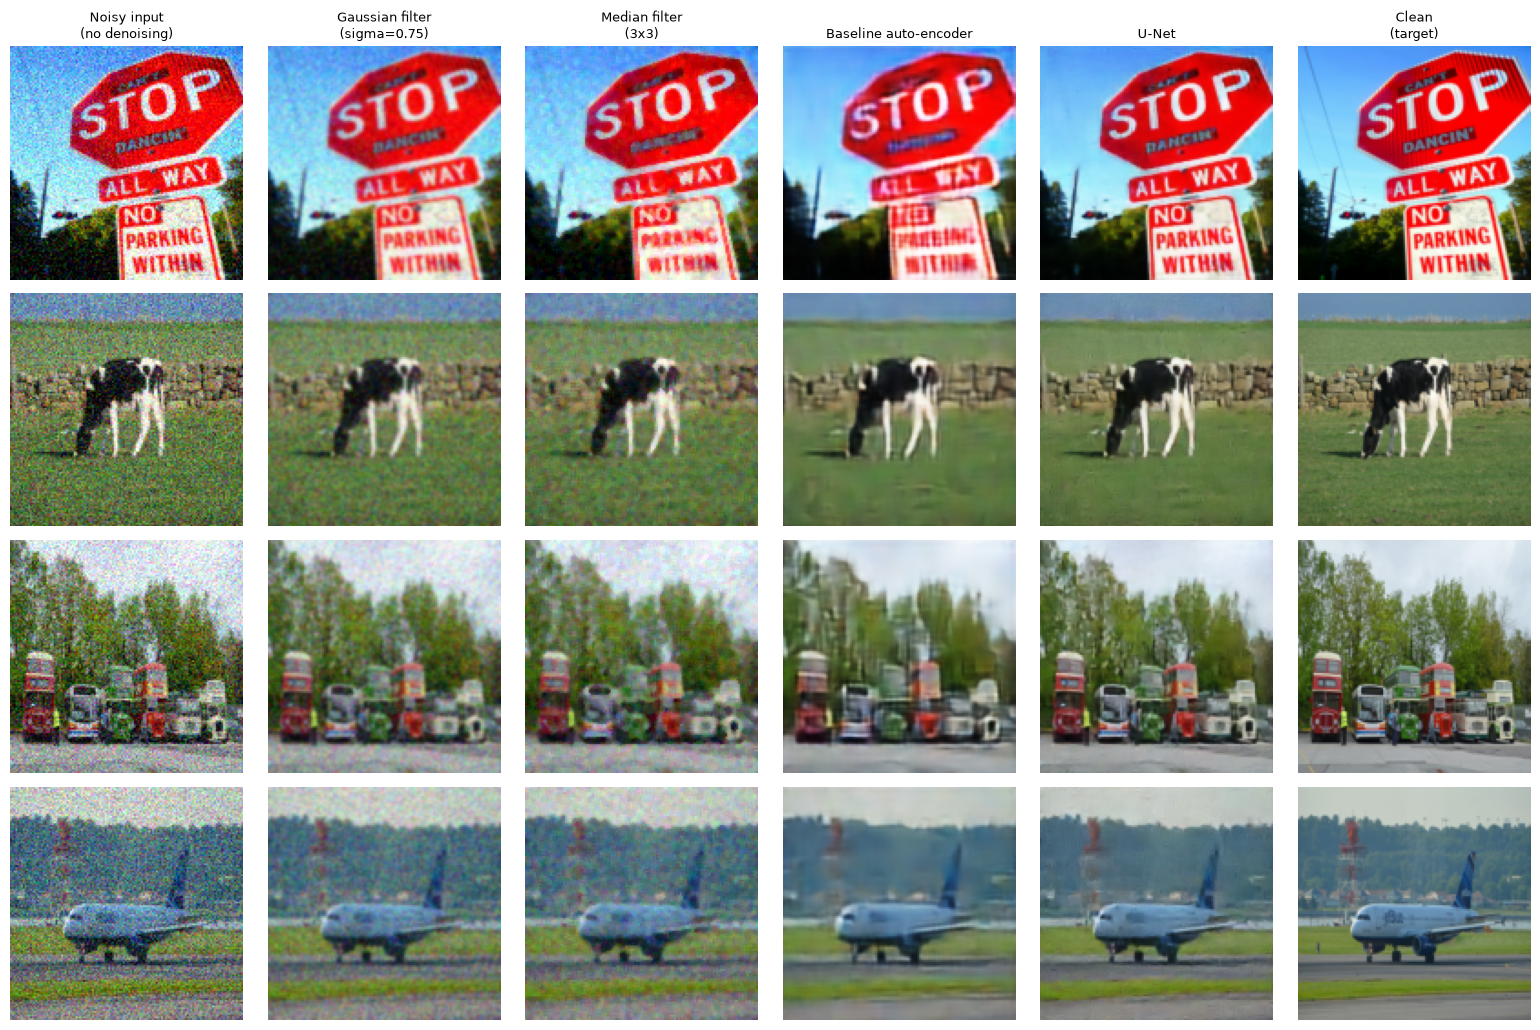

In [14]:
noisy_test, clean_test = next(iter(test_ds))
n_show = 4
columns = [(name, fn(noisy_test.numpy())) for name, fn in methods.items()] + [("Clean (target)", clean_test.numpy())]
fig, axes = plt.subplots(n_show, len(columns), figsize=(2.6 * len(columns), 2.6 * n_show))
for j, (name, images) in enumerate(columns):
    for i in range(n_show):
        axes[i, j].imshow(np.clip(images[i], 0, 1))
        axes[i, j].axis("off")
    axes[0, j].set_title(name.replace(" (", "\n("), fontsize=9)
plt.tight_layout()
plt.show()

## 6. Case study: what denoising gains, and what it costs

The subject does not define the case study. Our interpretation: a denoiser is only useful if the gain is clear **and** if we know what it costs. A model that removes noise by blurring everything would score well on a noisy image and still damage the photograph. So we look at four questions, all with numbers or images:

1. Does the gain hold when the noise level changes? (6.1)
2. What does the model do to an image that has **no** noise, and how much edge strength does it keep? (6.2)
3. What happens to a fine detail? (6.3)
4. Where are the remaining errors? (6.4)

Everything is measured on the test set at the training noise level (`NOISE_STD` = 0.1), except 6.1.

### 6.1 Other noise levels

The two auto-encoders were trained with a noise standard deviation of 0.1 only and are **not** trained again here: we measure how well they cope with noise they have not seen (robustness). Real scan noise will not be exactly the one we simulated, so this matters.

To stay fair with the classical filter, its `sigma` is chosen again on the validation set for each noise level (the auto-encoders cannot adapt, the filter can).

In [15]:
LEVELS = [0.05, 0.1, 0.2, 0.3]
SIGMAS = [0.5, 0.75, 1.0, 1.5, 2.0]
psnr_by_level, ssim_by_level, chosen_sigma = {}, {}, {}

for std in LEVELS:
    # Same fixed seed as before: for a given level every method gets the same noisy images.
    val_std = make_dataset(val_paths, noise_std=std, training=False)
    test_std = make_dataset(test_paths, noise_std=std, training=False)
    chosen_sigma[std] = max(SIGMAS, key=lambda s: score(val_std, gaussian(s))[0].mean())
    level_methods = {
        "Noisy input": lambda x: x,
        "Gaussian filter (tuned per level)": gaussian(chosen_sigma[std]),
        "Baseline auto-encoder": lambda x: autoencoder.predict_on_batch(x),
        "U-Net": lambda x: unet.predict_on_batch(x),
    }
    for name, denoise in level_methods.items():
        psnr, ssim = score(test_std, denoise)
        psnr_by_level.setdefault(name, {})[std] = float(psnr.mean())
        ssim_by_level.setdefault(name, {})[std] = float(ssim.mean())

print("Gaussian sigma chosen on the validation set, by noise level:", chosen_sigma)
print("\nTest PSNR (dB), by noise standard deviation (the models were trained at 0.1):")
display(pd.DataFrame(psnr_by_level).T.round(2))
print("Test SSIM:")
display(pd.DataFrame(ssim_by_level).T.round(3))

Gaussian sigma chosen on the validation set, by noise level: {0.05: 0.5, 0.1: 0.75, 0.2: 1.0, 0.3: 1.5}

Test PSNR (dB), by noise standard deviation (the models were trained at 0.1):


,0.05,0.10,0.20,0.30
Noisy input,26.26,20.46,14.96,12.08
Gaussian filter (tuned per level),29.13,26.10,22.65,20.58
Baseline auto-encoder,26.24,26.52,23.66,20.75
U-Net,30.55,30.08,22.05,17.92


Test SSIM:


,0.05,0.10,0.20,0.30
Noisy input,0.676,0.448,0.244,0.155
Gaussian filter (tuned per level),0.789,0.712,0.571,0.517
Baseline auto-encoder,0.801,0.804,0.665,0.517
U-Net,0.882,0.883,0.546,0.361


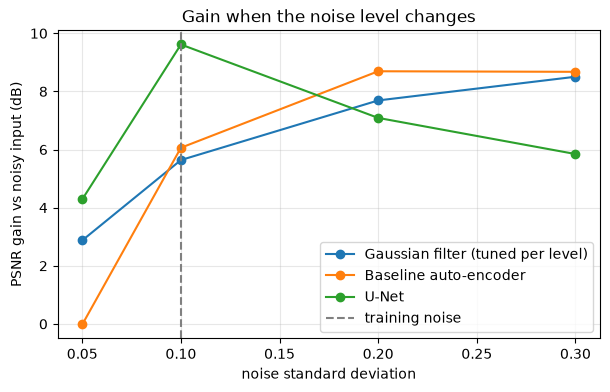

In [16]:
# PSNR gain compared with doing nothing, for each noise level.
fig, ax = plt.subplots(figsize=(7, 4))
for name in list(psnr_by_level)[1:]:
    gains = [psnr_by_level[name][s] - psnr_by_level["Noisy input"][s] for s in LEVELS]
    ax.plot(LEVELS, gains, marker="o", label=name)
ax.axvline(NOISE_STD, color="gray", linestyle="--", label="training noise")
ax.set_xlabel("noise standard deviation"); ax.set_ylabel("PSNR gain vs noisy input (dB)")
ax.set_title("Gain when the noise level changes"); ax.grid(alpha=0.3); ax.legend()
plt.show()

**Reading (numbers of our run, seed 42).**

- At the training level (0.1) the U-Net is far ahead (+9.6 dB). But it is the **least robust** model: at 0.2 and 0.3 its gain falls to +7.1 and +5.9 dB and it ends **below the tuned Gaussian filter** (22.05 against 22.65 dB at 0.2, 17.92 against 20.58 dB at 0.3; SSIM 0.36 against 0.52 at 0.3). This is the risk announced in 3.2: the skip connections carry the noisy pixels to the output, and a network trained at one noise level only learned how much to remove at that level. With more noise, part of it stays.
- The baseline copes better with stronger noise (+8.7 dB at 0.2 and 0.3, above the filter at 0.2) because its bottleneck forces a strong smoothing. With **less** noise than in training it is useless: at 0.05 its PSNR (26.24 dB) is the same as the noisy input (26.26 dB), because the little noise it removes is paid for by blur.
- Both models learned a single noise level. Real scans have an unknown and varying noise level: see the improvements in section 7.

### 6.2 The cost: what is lost when there is nothing to remove

Two measures of the damage, at the training noise level:

- **Clean image as input.** If we give a *clean* image to the denoiser, the ideal output is the same image. Any difference is detail that the model destroyed or invented. We report the PSNR and SSIM of the output against the input (a perfect denoiser would have no cost).
- **Edge strength.** The mean size of the differences between neighbouring pixels in the output, divided by the same quantity in the clean image: 1.0 means the edges are as strong as in the original, below 1.0 means the image is smoother (detail lost). The noisy input is above 1.0 because the noise creates false edges.

In [17]:
def edge_sum(images):
    """Sum of the absolute differences between neighbouring pixels (vertical + horizontal)."""
    dy, dx = tf.image.image_gradients(tf.convert_to_tensor(images))
    return float(tf.reduce_sum(tf.abs(dy) + tf.abs(dx)))


def edge_ratio(ds, denoise):
    """Edge strength of the denoised images divided by that of the clean images."""
    out_edges = clean_edges = 0.0
    for noisy_batch, clean_batch in ds:
        out_edges += edge_sum(denoise(noisy_batch.numpy()))
        clean_edges += edge_sum(clean_batch)
    return out_edges / clean_edges


clean_input_ds = make_dataset(test_paths, noisy=False)   # (clean, clean) pairs
cost_methods = {name: fn for name, fn in methods.items() if name != "Noisy input (no denoising)"}
cost_rows = {"Noisy input (no denoising)": {"edge strength (1.0 = original)": edge_ratio(test_ds, methods["Noisy input (no denoising)"])}}
for name, denoise in cost_methods.items():
    psnr_clean, ssim_clean = score(clean_input_ds, denoise)
    cost_rows[name] = {
        "edge strength (1.0 = original)": edge_ratio(test_ds, denoise),
        "PSNR on a clean input (dB)": float(psnr_clean.mean()),
        "SSIM on a clean input": float(ssim_clean.mean()),
    }
display(pd.DataFrame(cost_rows).T.round({"edge strength (1.0 = original)": 3, "PSNR on a clean input (dB)": 2, "SSIM on a clean input": 4}).fillna("-"))

,edge strength (1.0 = original),PSNR on a clean input (dB),SSIM on a clean input
Noisy input (no denoising),3.121,-,-
Gaussian filter (sigma=0.75),1.016,30.6,0.9336
Median filter (3x3),1.024,30.08,0.9086
Baseline auto-encoder,0.726,25.3,0.7912
U-Net,0.847,29.72,0.8707


**Reading.**

- On an image **without noise**, the Gaussian filter loses little (30.6 dB, SSIM 0.93), the U-Net a bit more (29.7 dB, 0.87) and the baseline a lot (25.3 dB, 0.79). Used on clean or lightly noisy scans, the baseline would degrade the photographs.
- Edge strength: the two auto-encoders keep 73 % (baseline) and 85 % (U-Net) of the edges of the original, so they smooth the image. The two filters are at 1.02, but this number must not be read as "no loss": their leftover noise creates false edges that hide their blur (the noisy input is at 3.1). The measure shows a loss only when it is clearly below 1, and must be read together with the clean-input test and the images below.

### 6.3 Zoom on a fine detail

The 32x32 area below (the lettering of the sign in the first test image, at the training noise level) is enlarged without interpolation, so that the pixels stay visible.

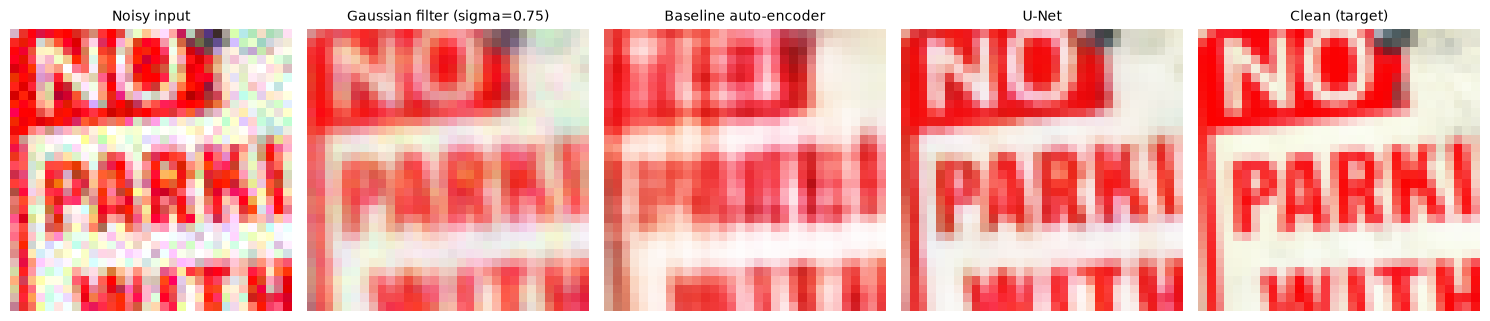

In [18]:
ROWS, COLS = slice(88, 120), slice(60, 92)   # lettering of the sign in image 0 (chosen by eye on the figure of 5.3)
zoom_titles = ["Noisy input", f"Gaussian filter (sigma={best_sigma})", "Baseline auto-encoder", "U-Net", "Clean (target)"]
zoom_images = [dict(columns)[name] for name in
               ["Noisy input (no denoising)", f"Gaussian filter (sigma={best_sigma})", "Baseline auto-encoder", "U-Net", "Clean (target)"]]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
for ax, title, images in zip(axes, zoom_titles, zoom_images):
    ax.imshow(np.clip(images[0][ROWS, COLS], 0, 1), interpolation="nearest")
    ax.set_title(title, fontsize=10); ax.axis("off")
plt.tight_layout()
plt.show()

**Reading.** The baseline smears the lettering: the shapes of the letters are hardly readable. The Gaussian filter keeps the letters but blurs them and leaves grain. The U-Net keeps the shape and the sharp edges of the letters, with softer colour transitions than the original.

### 6.4 Difference maps

Each map shows the absolute difference between the denoised image and the clean image (average of the three colour channels), with the **same colour scale** for every method: the brighter the pixel, the larger the remaining error. Errors that follow the edges of the objects are lost detail; errors spread everywhere are remaining noise.

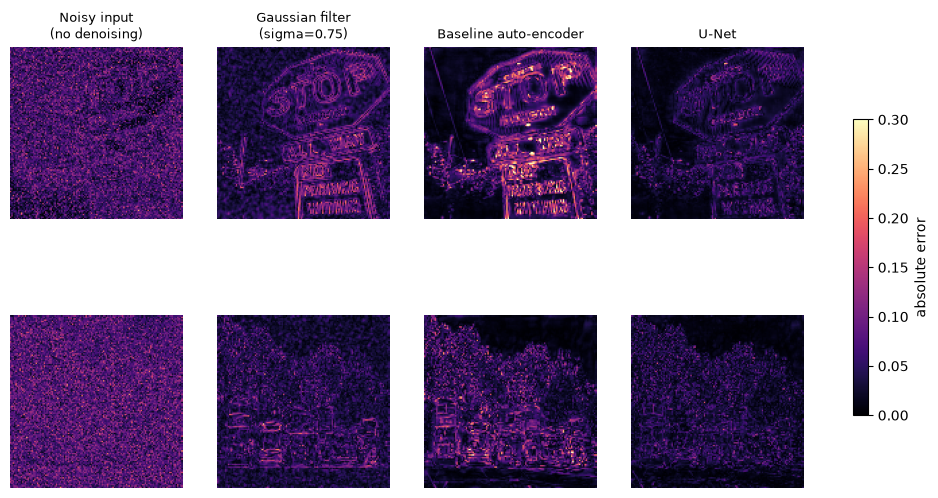

In [19]:
diff_names = ["Noisy input (no denoising)", f"Gaussian filter (sigma={best_sigma})", "Baseline auto-encoder", "U-Net"]
shown = [0, 2]   # the sign and the buses of the figure of 5.3
fig, axes = plt.subplots(len(shown), len(diff_names), figsize=(3.2 * len(diff_names), 3.2 * len(shown)))
for i, img in enumerate(shown):
    for j, name in enumerate(diff_names):
        error = np.abs(dict(columns)[name][img] - clean_test.numpy()[img]).mean(axis=-1)
        im = axes[i, j].imshow(error, cmap="magma", vmin=0, vmax=0.3)
        axes[i, j].axis("off")
        if i == 0:
            axes[i, j].set_title(name.replace(" (", "\n("), fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.6, label="absolute error")
plt.show()

**Reading.** The noisy input has a uniform speckle: pure noise. For the Gaussian filter the error is made of the edges of the objects and of a leftover speckle. The baseline has the largest errors, concentrated along the edges (outline and text of the sign, edge of the trees): this is the detail it lost. The U-Net has the lowest errors, mostly on the finest edges (the lettering).

## 7. Analysis, limits and improvements

*Numbers of our run (seed 42); if the models are trained again they must be read again.*

### 7.1 Analysis

**Baseline against U-Net.** On the test set the U-Net reaches 30.08 dB and an SSIM of 0.883, against 26.52 dB and 0.804 for the baseline (noisy input: 20.46 dB, 0.448). It costs 28 % more parameters (426,979 against 333,955), and it is the skip connections that make the difference, since the two networks have the same layers. The classical reference puts this in perspective: the baseline is only 0.4 dB above a simple Gaussian filter (26.10 dB), while the U-Net is 4 dB above.

**Why the baseline is limited: the bottleneck.** It compresses the image to 16x16x128 values and the decoder has to rebuild every detail from that. The result is smoothed: it keeps only 73 % of the edge strength, the lettering of the sign is smeared (6.3) and its largest errors follow the edges (6.4). The U-Net hands the encoder details back to the decoder at each resolution, which is what the figures show.

**Overfitting and underfitting.** For both models the training and the validation losses stay together (0.00258 and 0.00260 for the baseline, 0.00106 and 0.00108 for the U-Net): the variance is low and the models do not learn the images by heart. The remaining error comes from the limited capacity of the networks (bias), not from a lack of data. Two things help to explain it: the noise is drawn again at every epoch, so the models never see the same noisy image twice (a free data augmentation), and the validation noise is fixed, so the curves are comparable from one epoch to the next. Early stopping stopped the baseline at epoch 50; the U-Net used the 60 epochs allowed, but its curve is almost flat at the end.

**Robustness.** Both models learned a single noise level (0.1) and this is their main weakness (6.1). With stronger noise the U-Net falls below a Gaussian filter, because its skip connections let part of the noise through. With weaker noise the baseline brings no gain. Even on a clean image, the denoisers degrade the picture (6.2): the baseline loses 4.7 dB more than the Gaussian filter, the U-Net 0.9 dB.

### 7.2 Limits

- **Simulated noise.** We add Gaussian noise to clean photos. Real scan noise is different (grain, JPEG artifacts, blur, stains, correlated between pixels). The results above say how well the models remove *this* noise, not scan noise.
- **One noise level** for the first two models (section 8 then trains on a range of levels), and no tuning of the network (filters, learning rate) beyond the choices explained above.
- **One run per model.** GPU training is not exactly reproducible and we have no estimate of the variation between two trainings. A difference of a few tenths of a dB (like baseline against Gaussian filter) must not be over-interpreted; the 4 dB of the U-Net is clear.
- **The metrics are not the final goal.** PSNR and SSIM are not the captioning quality. We did not measure whether the captions improve after denoising (it belongs to the full workflow).
- **Resizing to 128x128** squashes the non-square images, and only photographs are used.

### 7.3 Improvements and recommendation

Improvements 1 and 3 were carried out in section 8: training on several noise levels fixed the robustness problem, and the residual formulation brought no gain.

1. **Train with several noise levels** (a random level for each image between 0.05 and 0.3): done in 8.1, it fixes the lack of robustness seen in 6.1. Still to test: noise outside this range.
2. **Estimate the noise before denoising**, and denoise only the images that need it: the models damage clean or lightly noisy images (6.2).
3. **Residual learning:** the network predicts the noise and we subtract it from the input. Done in 8.3 and 8.4: no gain over the direct U-Net.
4. **More realistic noise:** noise measured on real scans, blur and compression added to the training images.
5. **Calmer training:** a learning rate that decreases when the validation loss stops improving would smooth the spikes seen in the curves.
6. **Evaluate on the real task:** compare the captions of Deliverable 3 with and without denoising.

**Recommendation for TouNum:** use the U-Net trained on several noise levels (8.1) rather than the baseline or the U-Net of section 4. It is the best model for every level from 0.05 to 0.3 except at 0.1 where it is 0.3 dB below the first U-Net, and it treats clean images better. Before putting it in the workflow, test it on real scans: all our results are on simulated Gaussian noise. Measuring the noise level before denoising (improvement 2) remains a useful safety for images outside the range seen in training.

## 8. Putting the recommendation into practice

Section 7 listed improvements. Two of them are done here: **training on several noise levels** (8.1 and 8.2) and **an auto-encoder that predicts the noise instead of the image** (8.3, residual learning). The design of each step is fixed **before** looking at the test set; the validation set is used for every choice, and the test results are added as extra rows, never used to pick between variants.

### 8.1 Training the U-Net on several noise levels

**The problem (6.1).** The U-Net of section 4 saw one noise level only (0.1). With stronger noise it leaves part of the noise through and falls below a Gaussian filter.

**The change.** Every training image gets its **own** noise level, drawn uniformly between `NOISE_RANGE` = 0.05 and 0.3 (the noise itself is still redrawn at every epoch). The validation set also mixes the levels, with a fixed seed, so the early stopping does not choose the epoch that suits one level only.

**Everything else is identical to the U-Net of section 4.2:** same architecture, loss, optimizer, batch size, `MAX_EPOCHS` and `PATIENCE`. The only difference between the two models is the noise they were trained on. We also keep a constant learning rate on purpose: a decreasing one would be a second change and we would not know which one helps.

Validation with levels in (0.05, 0.3): noisy input vs clean: MSE 0.02837 | PSNR 15.47 dB
Reloaded d2_unet_multi_20261016_222108.weights.h5 (53 epochs), no training.


/home/asmax/ds-cesi/leyenda/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_2', because it has 2 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(store)


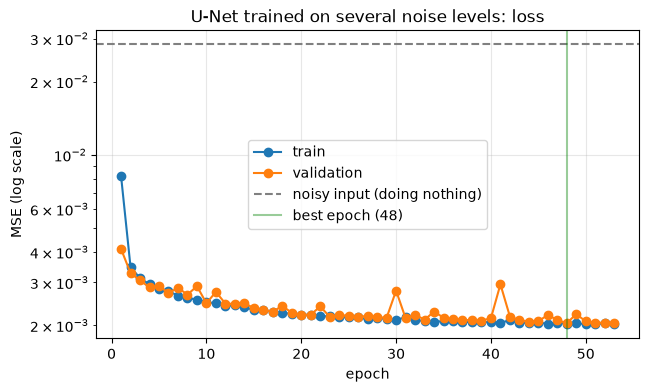

In [20]:
train_ms = make_dataset(train_paths, noise_std=NOISE_RANGE, training=True)
val_ms = make_dataset(val_paths, noise_std=NOISE_RANGE, training=False)

# Reference "doing nothing" on this mixed validation set (same loop as in section 4).
sq_err, n_values = 0.0, 0
for noisy_batch, clean_batch in val_ms:
    sq_err += float(tf.reduce_sum(tf.square(noisy_batch - clean_batch)))
    n_values += int(tf.size(clean_batch))
MSE_NOISY_MS = sq_err / n_values
print(f"Validation with levels in {NOISE_RANGE}: noisy input vs clean: MSE {MSE_NOISY_MS:.5f} | PSNR {10 * np.log10(1 / MSE_NOISY_MS):.2f} dB")

unet_multi = build_unet()
history_multi = train_or_load("unet_multi", unet_multi, train_ms, val_ms)
plot_loss(history_multi, "U-Net trained on several noise levels: loss", reference=MSE_NOISY_MS)

### 8.2 Results on several noise levels

Same test noise levels as in 6.1, and the same classical filter (its `sigma` was chosen on the validation set at each level). The two U-Nets are compared with the baseline and with the filter. The last lines measure the cost on a **clean** image (the test of 6.2), because a model trained on noisy images only could still damage clean ones.

Test PSNR (dB), by noise standard deviation:


,0.05,0.10,0.20,0.30
Noisy input,26.26,20.46,14.96,12.08
Gaussian filter (tuned per level),29.13,26.10,22.65,20.58
Baseline auto-encoder,26.24,26.52,23.66,20.75
U-Net,30.55,30.08,22.05,17.92
U-Net (several noise levels),31.76,29.75,26.86,24.93


Test SSIM:


,0.05,0.10,0.20,0.30
Noisy input,0.676,0.448,0.244,0.155
Gaussian filter (tuned per level),0.789,0.712,0.571,0.517
Baseline auto-encoder,0.801,0.804,0.665,0.517
U-Net,0.882,0.883,0.546,0.361
U-Net (several noise levels),0.921,0.881,0.801,0.727


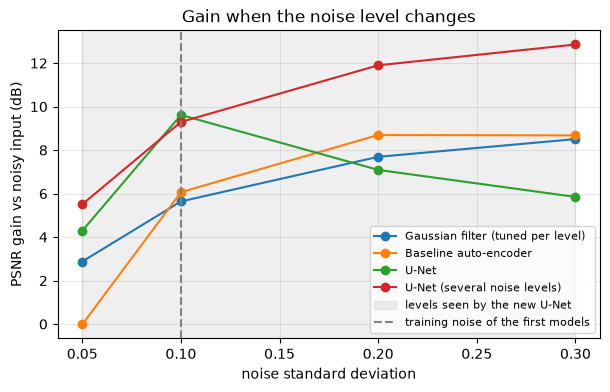

Clean input, U-Net (trained at 0.1): PSNR 29.72 dB | SSIM 0.8707
Clean input, U-Net (several noise levels): PSNR 33.08 dB | SSIM 0.9467


In [21]:
multi_name = "U-Net (several noise levels)"
for std in LEVELS:
    test_std = make_dataset(test_paths, noise_std=std, training=False)   # same images as in 6.1
    psnr, ssim = score(test_std, lambda x: unet_multi.predict_on_batch(x))
    psnr_by_level.setdefault(multi_name, {})[std] = float(psnr.mean())
    ssim_by_level.setdefault(multi_name, {})[std] = float(ssim.mean())

print("Test PSNR (dB), by noise standard deviation:")
display(pd.DataFrame(psnr_by_level).T.round(2))
print("Test SSIM:")
display(pd.DataFrame(ssim_by_level).T.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
for name in list(psnr_by_level)[1:]:
    gains = [psnr_by_level[name][s] - psnr_by_level["Noisy input"][s] for s in LEVELS]
    ax.plot(LEVELS, gains, marker="o", label=name)
ax.axvspan(*NOISE_RANGE, color="gray", alpha=0.12, label="levels seen by the new U-Net")
ax.axvline(NOISE_STD, color="gray", linestyle="--", label="training noise of the first models")
ax.set_xlabel("noise standard deviation"); ax.set_ylabel("PSNR gain vs noisy input (dB)")
ax.set_title("Gain when the noise level changes"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

# Cost on a clean image (test of section 6.2).
for name, model in [("U-Net (trained at 0.1)", unet), (multi_name, unet_multi)]:
    psnr_c, ssim_c = score(clean_input_ds, lambda x: model.predict_on_batch(x))
    print(f"Clean input, {name}: PSNR {psnr_c.mean():.2f} dB | SSIM {ssim_c.mean():.4f}")

**Reading (numbers of our run, seed 42).**

- **The robustness problem is fixed.** At 0.2 and 0.3 the new U-Net reaches 26.86 and 24.93 dB, against 22.05 and 17.92 dB for the U-Net trained at 0.1, and it is now above the tuned Gaussian filter (22.65 and 20.58 dB) and above the baseline (23.66 and 20.75 dB). The SSIM follows: 0.73 at 0.3, against 0.36 and 0.52. At 0.05 it is also better (31.76 dB, against 30.55 dB).
- **The price is small, at the old training level.** At 0.1 it gives 29.75 dB against 30.08 dB: 0.3 dB lower, the same order as the variation we can expect between two trainings (one run only, see 7.2). A model that has to cover a range of levels is slightly less specialised at each of them.
- **Clean images are better treated too:** 33.08 dB and an SSIM of 0.947, against 29.72 dB and 0.871 for the U-Net trained at 0.1 (and 30.60 dB, 0.934 for the Gaussian filter, 6.2). Having seen light noise (down to 0.05), it learned to leave an image almost untouched when there is little to remove. This is a result on the same kind of clean images as before (resized photographs, already smooth); it does not say that real clean scans would be as well treated.
- **Limit of this test:** all the test levels (0.05 to 0.3) are inside the range seen in training. We did not test noise outside of it (for example 0.5): the model may fall again outside the range it knows.

### 8.3 Residual learning: predicting the noise instead of the image

**The idea.** So far the network has to build the whole clean image from the noisy one. In a *residual* version, the network only predicts the **noise** and the output is the input minus this predicted noise: `output = noisy - predicted noise`. The noise is simpler than a photograph (it has no structure), so it may be easier to learn. This is the idea of a ResNet, a shortcut that adds (here subtracts) the input at the end, applied to the whole network. It is different from the skip connections of the U-Net, which are inside the network and concatenate features.

**What changes in the code.** Compared with `build_unet`, only the end changes:

- the last convolution has **no sigmoid**: the noise can be positive or negative (and not limited to [0, 1]);
- a `Subtract` layer computes `input - predicted noise`;
- a `ReLU(max_value=1.0)` keeps the result in [0, 1] (it is a clip: negative values become 0 and values above 1 become 1), like the sigmoid did.

At the beginning of the training the last convolution gives small values, so the output is close to the input: the network starts from "doing nothing" and only has to learn what to remove.

**Fair comparison.** This model is trained exactly like the one of 8.1 (same data with several noise levels, same loss, optimizer, `MAX_EPOCHS` and `PATIENCE`, same seed, same number of parameters). The only difference is the formulation of the output.

parameters: U-Net 426,979 | residual U-Net 426,979
Reloaded d2_unet_residual_20261016_230357.weights.h5 (51 epochs), no training.


/home/asmax/ds-cesi/leyenda/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_3', because it has 2 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(store)


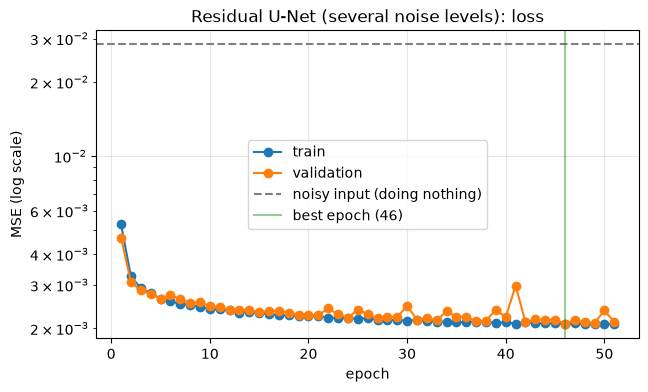

best validation MSE: U-Net 0.00204 | residual U-Net 0.00209


In [22]:
def build_residual_unet():
    """Same layers as build_unet, but the network predicts the noise: output = input - predicted noise."""
    keras.utils.set_random_seed(SEED)

    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))

    # Encoder and decoder: identical to build_unet.
    c1 = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)    # 128x128
    x = keras.layers.MaxPooling2D(2)(c1)                                          # 64
    c2 = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)         # 64x64
    x = keras.layers.MaxPooling2D(2)(c2)                                          # 32
    c3 = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)        # 32x32
    x = keras.layers.MaxPooling2D(2)(c3)                                          # 16 (bottleneck)

    x = keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)                                           # 32
    x = keras.layers.Concatenate()([x, c3])
    x = keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)                                           # 64
    x = keras.layers.Concatenate()([x, c2])
    x = keras.layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = keras.layers.UpSampling2D(2)(x)                                           # 128
    x = keras.layers.Concatenate()([x, c1])

    # The end is different: the convolution gives the predicted noise (no activation: it can be negative),
    # the output is the input minus this noise, kept in [0, 1] by ReLU(max_value=1).
    predicted_noise = keras.layers.Conv2D(3, 3, padding="same")(x)
    outputs = keras.layers.Subtract()([inputs, predicted_noise])
    outputs = keras.layers.ReLU(max_value=1.0)(outputs)

    model = keras.Model(inputs, outputs, name="residual_unet")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return model


unet_residual = build_residual_unet()
print(f"parameters: U-Net {unet.count_params():,} | residual U-Net {unet_residual.count_params():,}")
history_residual = train_or_load("unet_residual", unet_residual, train_ms, val_ms)
plot_loss(history_residual, "Residual U-Net (several noise levels): loss", reference=MSE_NOISY_MS)

# The two models share data and settings: their validation losses can be compared directly.
best_multi, best_residual = min(history_multi["val_loss"]), min(history_residual["val_loss"])
print(f"best validation MSE: U-Net {best_multi:.5f} | residual U-Net {best_residual:.5f}")

### 8.4 Results of the residual U-Net

Same test levels and same comparison as in 8.2, with one more row.

Test PSNR (dB), by noise standard deviation:


,0.05,0.10,0.20,0.30
Noisy input,26.26,20.46,14.96,12.08
Gaussian filter (tuned per level),29.13,26.10,22.65,20.58
Baseline auto-encoder,26.24,26.52,23.66,20.75
U-Net,30.55,30.08,22.05,17.92
U-Net (several noise levels),31.76,29.75,26.86,24.93
Residual U-Net (several noise levels),31.82,29.69,26.76,24.73


Test SSIM:


,0.05,0.10,0.20,0.30
Noisy input,0.676,0.448,0.244,0.155
Gaussian filter (tuned per level),0.789,0.712,0.571,0.517
Baseline auto-encoder,0.801,0.804,0.665,0.517
U-Net,0.882,0.883,0.546,0.361
U-Net (several noise levels),0.921,0.881,0.801,0.727
Residual U-Net (several noise levels),0.923,0.881,0.798,0.715


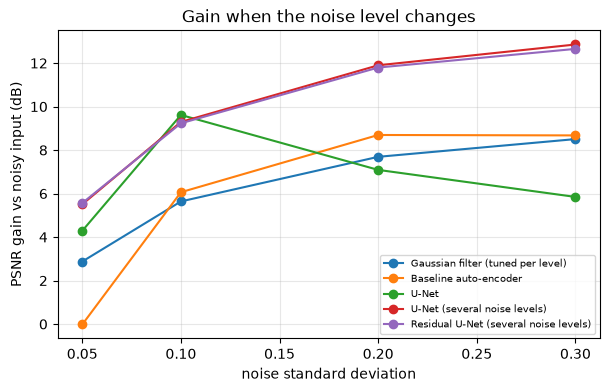

Clean input, Residual U-Net (several noise levels): PSNR 33.40 dB | SSIM 0.9458


In [23]:
residual_name = "Residual U-Net (several noise levels)"
for std in LEVELS:
    test_std = make_dataset(test_paths, noise_std=std, training=False)
    psnr, ssim = score(test_std, lambda x: unet_residual.predict_on_batch(x))
    psnr_by_level.setdefault(residual_name, {})[std] = float(psnr.mean())
    ssim_by_level.setdefault(residual_name, {})[std] = float(ssim.mean())

print("Test PSNR (dB), by noise standard deviation:")
display(pd.DataFrame(psnr_by_level).T.round(2))
print("Test SSIM:")
display(pd.DataFrame(ssim_by_level).T.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
for name in list(psnr_by_level)[1:]:
    gains = [psnr_by_level[name][s] - psnr_by_level["Noisy input"][s] for s in LEVELS]
    ax.plot(LEVELS, gains, marker="o", label=name)
ax.set_xlabel("noise standard deviation"); ax.set_ylabel("PSNR gain vs noisy input (dB)")
ax.set_title("Gain when the noise level changes"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.show()

psnr_c, ssim_c = score(clean_input_ds, lambda x: unet_residual.predict_on_batch(x))
print(f"Clean input, {residual_name}: PSNR {psnr_c.mean():.2f} dB | SSIM {ssim_c.mean():.4f}")

**Reading (numbers of our run, seed 42).**

- **No gain.** The residual U-Net is at the same level as the direct one, with differences of 0.2 dB or less on every noise level (for example 26.76 against 26.86 dB at 0.2 and 24.73 against 24.93 dB at 0.3), which is the order of magnitude of the variation between two trainings. Its best validation MSE is 0.00209, against 0.00204. On a clean image it is slightly better (33.40 against 33.08 dB), but with the same SSIM (0.946 and 0.947): we do not draw a conclusion from this.
- **Why, probably.** The U-Net already has a skip connection from the first layer to the last one, so the end of the network can copy the details of its input by itself; writing the output as `input - noise` adds little (this is our explanation, we did not test it).
- **Conclusion.** The idea does not help on this problem, so we keep the **direct U-Net trained on several noise levels** (8.1), which is simpler to explain. A negative result is still a result: it was tested, not assumed.